# 03 Model Building and Comparison

This notebook builds dropout classifiers, compares imbalance strategies without leakage, and evaluates both ranking quality and the recall needed for early support.

### What and why
Load engineered features and create the fixed stratified 80/20 split. Feature engineering is performed before splitting because it uses only row-wise values and no target information.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from data_utils import load_data, prepare_model_data, split_data
from model_utils import make_pipeline
from plot_utils import set_style, save_figure

set_style()
data = load_data()
model_data = prepare_model_data(data)
X_train, X_test, y_train, y_test = split_data(model_data)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train dropout rate:", y_train.mean().round(3), "Test dropout rate:", y_test.mean().round(3))


Train: (3539, 40) Test: (885, 40)
Train dropout rate: 0.321 Test dropout rate: 0.321


### What and why
Train nine combinations. Cross-validation happens on the training data, and SMOTE is inside the imbalanced-learn pipeline so synthetic rows never enter validation or test data.

In [2]:
models = ["logistic_regression", "random_forest", "xgboost"]
strategies = ["none", "class_weight", "smote"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
fitted = {}

for model_name in models:
    for strategy in strategies:
        pipeline = make_pipeline(model_name, X_train.columns, strategy)
        cv_recall = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="recall", n_jobs=1).mean()
        pipeline.fit(X_train, y_train)
        probabilities = pipeline.predict_proba(X_test)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)
        row = {
            "model": model_name,
            "imbalance_strategy": strategy,
            "cv_recall": cv_recall,
            "precision": precision_score(y_test, predictions, zero_division=0),
            "recall": recall_score(y_test, predictions),
            "f1": f1_score(y_test, predictions),
            "roc_auc": roc_auc_score(y_test, probabilities),
            "pr_auc": average_precision_score(y_test, probabilities),
        }
        rows.append(row)
        fitted[(model_name, strategy)] = pipeline

comparison = pd.DataFrame(rows).sort_values(["recall", "pr_auc"], ascending=False)
comparison.to_csv("../results/tables/model_comparison.csv", index=False)
display(comparison.round(3))


,model,imbalance_strategy,cv_recall,precision,recall,f1,roc_auc,pr_auc
1,logistic_regression,class_weight,0.819,0.789,0.845,0.816,0.934,0.900
2,logistic_regression,smote,0.814,0.795,0.835,0.814,0.932,0.898
4,random_forest,class_weight,0.795,0.794,0.827,0.810,0.930,0.900
8,xgboost,smote,0.774,0.851,0.824,0.837,0.939,0.913
5,random_forest,smote,0.783,0.807,0.824,0.815,0.933,0.903
6,xgboost,none,0.747,0.854,0.785,0.818,0.943,0.915
7,xgboost,class_weight,0.747,0.854,0.785,0.818,0.943,0.915
0,logistic_regression,none,0.726,0.879,0.743,0.805,0.934,0.901
3,random_forest,none,0.710,0.874,0.732,0.797,0.930,0.901


### What and why
Plot the test metrics so the trade-off is visible. Recall is emphasized because a false negative means an at-risk student may not receive support.

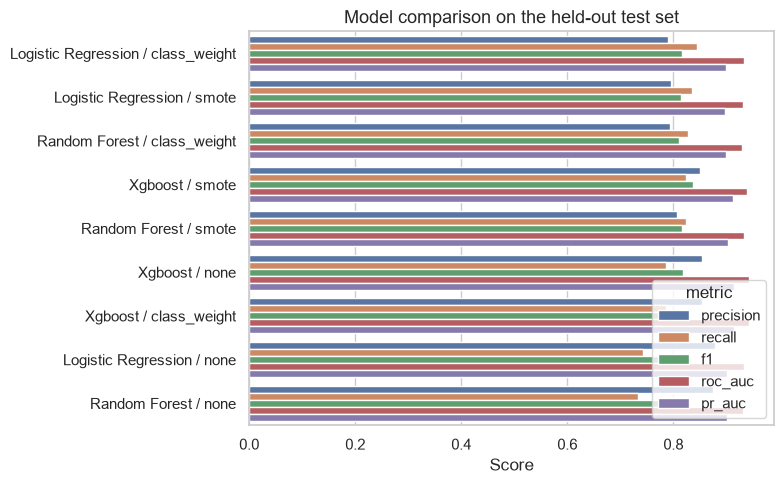

In [3]:
plot_data = comparison.melt(
    id_vars=["model", "imbalance_strategy"],
    value_vars=["precision", "recall", "f1", "roc_auc", "pr_auc"],
    var_name="metric", value_name="score",
)
plot_data["configuration"] = plot_data["model"].str.replace("_", " ").str.title() + " / " + plot_data["imbalance_strategy"]
sns.barplot(data=plot_data, x="score", y="configuration", hue="metric")
plt.title("Model comparison on the held-out test set")
plt.xlabel("Score")
plt.ylabel("")
save_figure("fig06_model_comparison.png")
plt.show()


### What and why
Select the configuration with the strongest recall, breaking ties with PR-AUC. Show its confusion matrix and ROC curve to make its errors and ranking ability concrete.

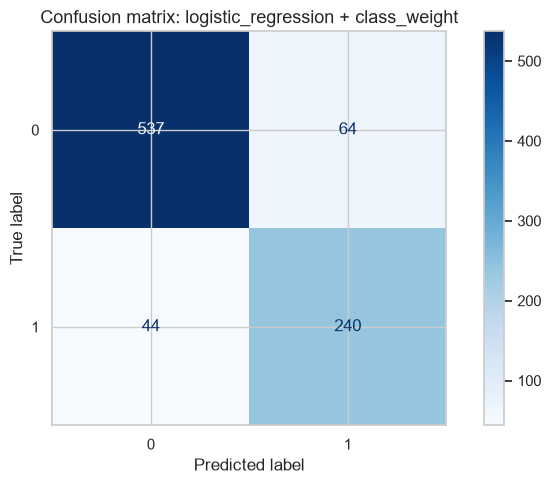

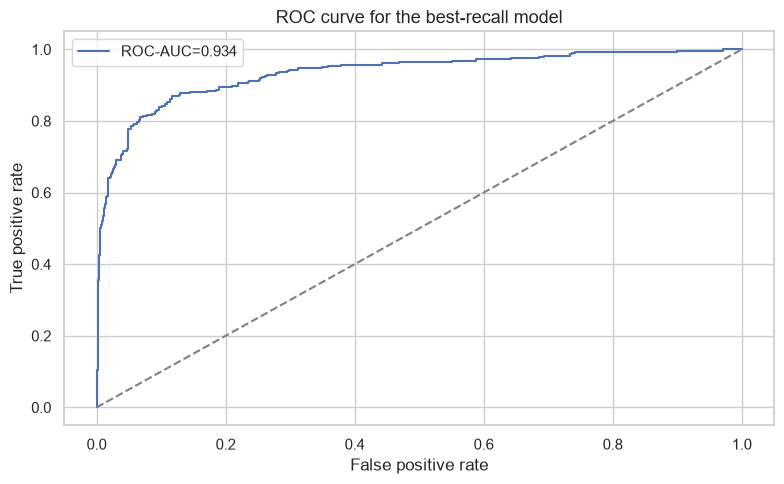

In [4]:
best_row = comparison.iloc[0]
best_key = (best_row["model"], best_row["imbalance_strategy"])
best_model = fitted[best_key]
best_probabilities = best_model.predict_proba(X_test)[:, 1]
best_predictions = (best_probabilities >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, cmap="Blues")
plt.title(f"Confusion matrix: {best_key[0]} + {best_key[1]}")
save_figure("fig07_best_confusion_matrix.png")
plt.show()

fpr, tpr, _ = roc_curve(y_test, best_probabilities)
plt.plot(fpr, tpr, label=f"ROC-AUC={roc_auc_score(y_test, best_probabilities):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.title("ROC curve for the best-recall model")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
save_figure("fig08_best_roc_curve.png")
plt.show()


## Conclusion

The comparison table records precision, recall, F1, ROC-AUC, and PR-AUC for every model and imbalance strategy. Recall is the primary selection criterion because early-warning systems should avoid missing students who may need help.